# Credit Pre-Screening Engine — Loan Intake Optimisation

**Calibo AI Academy · Path 2 · KLU Batch · Phase 2 — Supervised Learning Part 1**
**Mini Use Case 02 · BFSI — Retail Lending**

---

### Team

**Team: Batch 9**

| Member | Role | Sections owned |
|---|---|---|
| **Mohammed Mutee Ruknuddin** | Data Analyst | Step 5.1 · CBIM Problem Canvas |
| **Mohammed Saalif Udyawar** | Insights Analyst | Steps 5.2 and 5.3 |
| **Mulla Javeed** | Model Builder | Steps 5.4 and 5.5 |
| **Nagothu Varshitha** | Policy Synthesiser | Steps 5.6 and 5.7 |

> The CBIM Problem Canvas below was completed by all four members together, before any code was written.
> The notebook was run end-to-end from a clean kernel by a member who did not write the sections being tested.

**Dataset:** `MUC02_Credit_PreScreening_Dataset.csv` — 12,000 applications, April–September 2026
**Target:** `decision` (Approved / Declined) — modelled as **Declined = 1**

---

# CBIM Problem Canvas

*Completed by all four members together, before any analysis. 15–20 minutes.*

### Situation (S)
A mid-size private bank's retail lending unit receives about **3,000 unsecured personal loan applications a month** from salaried, self-employed, business-owner and gig applicants across Tier 1–3 cities. Every application is reviewed manually by a credit analyst, taking roughly **25 minutes each** — about 1,250 analyst hours a month.

### Complication (C)
About **47% of applications are declined**, and a large share of those are decided in the first minute because the credit score is far below the bank's working floor or existing EMIs already consume most of the applicant's income. Analyst time is spent on clear-cut declines rather than on borderline cases that need judgement; good applicants wait longer in the queue; and the bank cannot grow intake without hiring proportionally.

### Question (Q)
**Which applications can be removed from the manual review queue automatically, and at what model-confidence threshold, without wrongly declining more than 5% of applicants the credit team would have approved?**

The decision this enables is operational, not analytical: the bank introduces an auto-decline lane at a stated confidence level and re-deploys the freed analyst hours onto applications that genuinely need a human.

### SSOT (single source of truth)
`MUC02_Credit_PreScreening_Dataset.csv` — 12,000 applications received between April and September 2026, one row per application, 19 columns, with the credit team's final decision recorded.

The critical qualification: **the `decision` column is the credit team's past judgement, not whether the customer repaid.** The model therefore learns to reproduce historical analyst behaviour, including any inconsistency or bias in it. Model error is measured against what an analyst would have decided, not against actual credit risk.

### Success definition
Not accuracy. The pre-screener is good enough when, at the chosen threshold, **no more than 5% of auto-declined applications are ones the credit team would have approved** (the bank's stated risk appetite), while the volume removed is large enough to matter — stated explicitly in **applications per month and analyst hours per month**. A secondary condition: the model must not be trusted on segments where its accuracy is near chance, and those segments must be named.

### Primary stakeholder
The **Credit Policy Analyst**, who owns the recommendation and must defend it to the Head of Retail Lending.

Also affected: the **Head of Retail Lending** (approves the change, wants hours and risk); the **credit analysts**, whose queue composition changes as easy declines leave and hard cases remain; and the **applicants**, in particular those declined without a human ever reading their file.

---

## Setup

One shared chart style is defined here and used by every section, so the notebook reads as one piece of work rather than four.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             roc_auc_score, precision_score, recall_score)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

# ---- shared chart style (used by all sections) ----
INK, INK2, MUTED, GRID, BASE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, RED, PALE = "#2a78d6", "#eb6834", "#d03b3b", "#b7d3f6"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "font.size": 10, "axes.edgecolor": BASE, "axes.labelcolor": INK2,
    "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": False,
})

def style_axes(ax, ylabel=None, ymax=None, horizontal=False):
    '''Consistent axis treatment: no top/right/left spine, recessive gridlines.'''
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(BASE)
    (ax.xaxis if horizontal else ax.yaxis).grid(True, color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)
    if ylabel:
        ax.set_ylabel(ylabel, color=INK2, fontsize=9)
    if ymax:
        ax.set_ylim(0, ymax)
    return ax

def label_bars(ax, bars, values, fmt="{:.1f}%", pad=1.5):
    '''Direct value labels on bars - every chart in this notebook labels its marks.'''
    for bar, value in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + pad,
                fmt.format(value), ha="center", va="bottom",
                fontsize=9, color=INK, fontweight="bold")

RANDOM_STATE = 42
print("Setup complete.")

Setup complete.


---

# Step 5.1 — Load, inspect and clean

*Section owner: Mohammed Mutee Ruknuddin — Data Analyst*

Three things in this dataset need a decision before any modelling. Each one is investigated first, then fixed, and the reasoning for every choice is recorded below — a reviewer at the bank should be able to read these notes and agree with each one.

In [2]:
df = pd.read_csv("MUC02_Credit_PreScreening_Dataset.csv")

print("Shape:", df.shape)
print("\nDate range:", df["application_date"].min(), "to", df["application_date"].max())
print("Duplicate application_ids:", df["application_id"].duplicated().sum())
print("\nData types:")
print(df.dtypes)
print("\nNull values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

approval_rate = (df["decision"] == "Approved").mean()
print(f"\nDecision split:\n{df['decision'].value_counts()}")
print(f"\nOverall approval rate: {approval_rate:.2%}")

Shape: (12000, 19)

Date range: 2026-04-01 to 2026-09-30
Duplicate application_ids: 0

Data types:
application_id               str
application_date             str
age                        int64
gender                       str
city                         str
city_tier                  int64
employment_type              str
years_in_current_job     float64
monthly_income           float64
existing_emi             float64
credit_score             float64
credit_history_months      int64
num_active_loans           int64
delinquencies_24m          int64
loan_purpose                 str
loan_amount              float64
tenure_months              int64
proposed_emi             float64
decision                     str
dtype: object

Null values:
monthly_income     441
credit_score      1039
dtype: int64

Decision split:
decision
Approved    6353
Declined    5647
Name: count, dtype: int64

Overall approval rate: 52.94%


**The target is close to balanced** — 52.9% approved, 47.1% declined. That means accuracy is not actively misleading here, but it is still not the number the bank cares about; that comes in Step 5.5.

Two columns have nulls: `monthly_income` (441) and `credit_score` (1,039). Neither should be handled by a blanket `dropna()` — investigated one at a time below.

In [3]:
# ---- Issue 1: missing monthly_income - is it random? ----
missing_income = (df.groupby("employment_type")
                    .agg(applications=("application_id", "count"),
                         missing_income=("monthly_income", lambda s: s.isnull().sum())))
missing_income["pct_missing"] = (missing_income["missing_income"] /
                                 missing_income["applications"] * 100).round(2)
print("Missing monthly_income by employment type:")
print(missing_income.sort_values("pct_missing", ascending=False))

Missing monthly_income by employment type:
                            applications  missing_income  pct_missing
employment_type                                                      
Business Owner                      1749             227        12.98
Self-Employed Professional          1428             154        10.78
Salaried                            7057              49         0.69
Gig / Contract                      1766              11         0.62


**The missingness is not random.** It is concentrated in the two self-employed categories — Business Owner (12.98%) and Self-Employed Professional (10.78%) — against under 0.7% for Salaried and Gig/Contract applicants, a roughly 18-fold difference.

That makes sense: an applicant without a salary slip has no single clean number to declare. **The missingness is itself information about the applicant**, which is why dropping these rows would quietly delete a specific customer segment rather than removing noise.

In [4]:
# ---- Issue 2: blank credit_score - error, or a real group? ----
no_score = df["credit_score"].isnull()

print(f"Applications with no credit score: {no_score.sum()} ({no_score.mean():.1%})")
print(f"credit_history_months values for them: {sorted(df.loc[no_score, 'credit_history_months'].unique())}")
print(f"Rows with 0 credit history BUT a score present: "
      f"{((df['credit_history_months'] == 0) & df['credit_score'].notnull()).sum()}")
print(f"\nMean age  - no score: {df.loc[no_score, 'age'].mean():.1f} | scored: {df.loc[~no_score, 'age'].mean():.1f}")
print(f"Approval  - no score: {(df.loc[no_score, 'decision'] == 'Approved').mean():.1%} "
      f"| scored: {(df.loc[~no_score, 'decision'] == 'Approved').mean():.1%}")

Applications with no credit score: 1039 (8.7%)
credit_history_months values for them: [np.int64(0)]
Rows with 0 credit history BUT a score present: 0

Mean age  - no score: 29.9 | scored: 33.5
Approval  - no score: 53.9% | scored: 52.9%


**These are not errors.** `credit_history_months` is **0 for all 1,039** of them, and there is not a single row in the file with zero credit history but a score present. These are **new-to-credit (NTC)** applicants — people who have never borrowed, so the bureau has nothing to score.

Two further checks confirm they are a genuine population rather than corrupt data:

- They are **younger** (mean age 29.9 vs 33.5), exactly as expected for first-time borrowers.
- They are approved **53.9%** of the time — essentially the house rate. The credit team is actively lending to them using judgement.

Dropping them would remove 8.7% of applicants, skewed young, and would delete a segment the bank serves. **They are kept and flagged with `is_ntc`.**

In [5]:
# ---- Issue 3: implausible monthly_income ----
print(df["monthly_income"].describe().round(0))

implausible = df["monthly_income"] > 600_000
print(f"\nApplications with monthly_income > Rs 6,00,000: {implausible.sum()}")
print(f"Employment types involved: {df.loc[implausible, 'employment_type'].unique()}")
print("\nThese values divided by 12:")
check = df.loc[implausible, ["employment_type", "monthly_income"]].copy()
check["as_monthly"] = (check["monthly_income"] / 12).round(0)
print(check.sort_values("monthly_income", ascending=False).to_string(index=False))

count      11559.0
mean       60315.0
std        48891.0
min        12000.0
25%        33500.0
50%        50500.0
75%        74750.0
max      1656000.0
Name: monthly_income, dtype: float64

Applications with monthly_income > Rs 6,00,000: 12
Employment types involved: <StringArray>
['Salaried']
Length: 1, dtype: str

These values divided by 12:
employment_type  monthly_income  as_monthly
       Salaried       1656000.0    138000.0
       Salaried       1254000.0    104500.0
       Salaried       1212000.0    101000.0
       Salaried       1068000.0     89000.0
       Salaried        990000.0     82500.0
       Salaried        984000.0     82000.0
       Salaried        972000.0     81000.0
       Salaried        900000.0     75000.0
       Salaried        870000.0     72500.0
       Salaried        702000.0     58500.0
       Salaried        690000.0     57500.0
       Salaried        618000.0     51500.0


**Twelve rows, all Salaried, almost certainly annual income typed into a monthly field.** The evidence is that dividing by 12 puts *every one* of them back into a normal salaried band (₹51,500–₹1,38,000) — a data-entry explanation that reproduces plausible values across all 12 cases is far more likely than twelve genuine ₹6 lakh+ monthly salaries.

Leaving them uncorrected matters more than the row count suggests. An applicant with ₹16.5 lakh "monthly" income and a ₹44,400 EMI gets a FOIR of 0.037, which would teach the model that very large loans are effortless — and FOIR turns out to be the strongest feature in the whole dataset.

**Decision: divide by 12** rather than drop, because these are real applications whose income is recoverable.

### Cleaning log

Applied in this order, because each step feeds the next:

| # | Decision | Rationale |
|---|---|---|
| 1 | **12 incomes > ₹6L ÷ 12** | Annual entered as monthly; all Salaried; every value becomes plausible after division. Done **first** so it cannot pollute the medians used in step 2 or the FOIR built in Step 5.3. |
| 2 | **441 missing incomes → median of their employment type** | Income differs sharply by employment type (₹28,000 gig vs ₹75,000 self-employed professional). A global median would overstate gig incomes by ~80% and understate self-employed incomes by a third — and 86% of the missing values are self-employed, so it would inflate their FOIR and teach the model a bias we introduced ourselves. Median not mean, because income is right-skewed. |
| 3 | **1,039 blank credit scores → kept, flagged `is_ntc`** | Genuine new-to-credit applicants, not errors. Dropping removes 8.7% of applicants, skewed young. Score is median-filled for the model in Step 5.4; the flag tells the model which rows were filled. |

**Not changed:** 139 rows have a FOIR above 1.0 even after the ÷12 fix — applicants whose combined EMIs would exceed their whole monthly income. These are plausible (people do apply for loans they cannot afford) and 18.7% of them were still approved, so they are real applications and are kept.

In [6]:
# ---- Apply the cleaning, in the order justified above ----

# 1. annual-as-monthly correction (must run before medians and before FOIR)
df.loc[df["monthly_income"] > 600_000, "monthly_income"] /= 12

# 2. impute missing income with the median for that employment type
income_medians = df.groupby("employment_type")["monthly_income"].median()
print("Median monthly income used for imputation:")
print(income_medians.round(0).to_string())
df["monthly_income"] = df["monthly_income"].fillna(df["employment_type"].map(income_medians))

# 3. flag new-to-credit applicants (BEFORE the score is filled in Step 5.4)
df["is_ntc"] = df["credit_score"].isnull().astype(int)

# helper for the approval-rate analysis that follows
df["approved"] = (df["decision"] == "Approved").astype(int)

print(f"\nMax monthly income after correction: Rs {df['monthly_income'].max():,.0f}")
print(f"Remaining nulls in monthly_income: {df['monthly_income'].isnull().sum()}")
print(f"New-to-credit applicants flagged:   {df['is_ntc'].sum()} ({df['is_ntc'].mean():.1%})")
print(f"\nRows retained: {len(df):,} of 12,000 - no applications were dropped.")

Median monthly income used for imputation:
employment_type
Business Owner                69500.0
Gig / Contract                28000.0
Salaried                      50000.0
Self-Employed Professional    75000.0

Max monthly income after correction: Rs 546,000
Remaining nulls in monthly_income: 0
New-to-credit applicants flagged:   1039 (8.7%)

Rows retained: 12,000 of 12,000 - no applications were dropped.


---

# Step 5.2 — What drives approval today?

*Section owner: Mohammed Saalif Udyawar — Insights Analyst*

Before building anything, find out what the credit team actually does. If the model later returns the same drivers that show up here, we have evidence it learned the bank's real credit policy rather than noise.

In [7]:
def score_band(score):
    if pd.isnull(score):
        return "No score"
    for upper, label in [(600, "<600"), (650, "600-649"), (700, "650-699"),
                         (750, "700-749"), (800, "750-799")]:
        if score < upper:
            return label
    return "800+"

BAND_ORDER = ["<600", "600-649", "650-699", "700-749", "750-799", "800+", "No score"]
df["score_band"] = df["credit_score"].apply(score_band)

by_score = (df.groupby("score_band")
              .agg(applications=("approved", "size"), approval_rate=("approved", "mean"))
              .reindex(BAND_ORDER))
by_score["approval_rate"] = (by_score["approval_rate"] * 100).round(1)
print(by_score)

below_650 = df[df["credit_score"] < 650]
print(f"\nBelow 650 overall: {len(below_650):,} applications, "
      f"{below_650['approved'].mean():.1%} approved")

            applications  approval_rate
score_band                             
<600                 246            2.0
600-649              933            3.2
650-699             2529           32.5
700-749             3377           54.4
750-799             2526           77.2
800+                1350           85.2
No score            1039           53.9

Below 650 overall: 1,179 applications, 3.0% approved


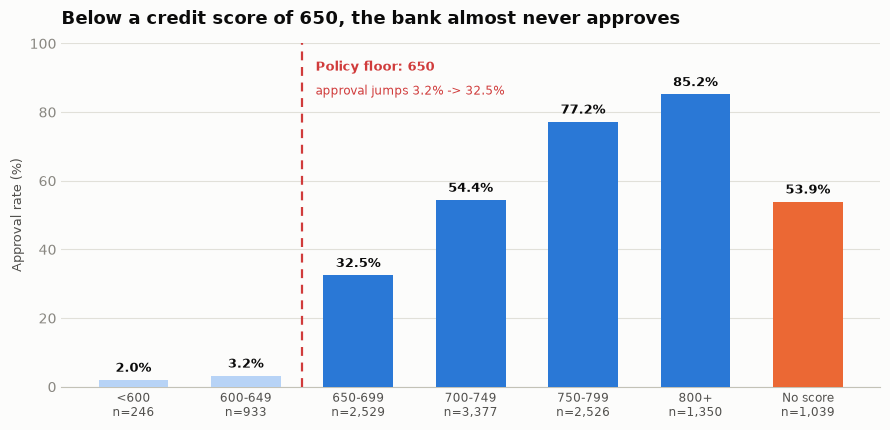

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.4))
colors = [PALE, PALE, BLUE, BLUE, BLUE, BLUE, ORANGE]
bars = ax.bar(range(len(BAND_ORDER)), by_score["approval_rate"], color=colors, width=0.62, zorder=3)
label_bars(ax, bars, by_score["approval_rate"].values)

ax.set_xticks(range(len(BAND_ORDER)))
ax.set_xticklabels([f"{b}\nn={int(n):,}" for b, n in zip(BAND_ORDER, by_score["applications"])],
                   fontsize=8.5, color=INK2)
style_axes(ax, "Approval rate (%)", 100)

ax.axvline(1.5, color=RED, lw=1.6, ls=(0, (4, 3)), zorder=4)
ax.text(1.62, 95, "Policy floor: 650", color=RED, fontsize=9.5, fontweight="bold", va="top")
ax.text(1.62, 88, "approval jumps 3.2% -> 32.5%", color=RED, fontsize=8.5, va="top")

ax.set_title("Below a credit score of 650, the bank almost never approves",
             fontsize=13, fontweight="bold", color=INK, loc="left", pad=14)
plt.tight_layout()
plt.show()

### The bank has an unwritten credit score floor at 650

Below 650, approval is **3.0%** across 1,179 applications. Immediately above it, 32.5%, rising to 85.2% at 800+. The jump is roughly **tenfold across a single one-point boundary.**

This is not a gradient, it is a rule. No one has written "650" into the credit policy, but every analyst applies it. **That is exactly the kind of rule a pre-screener can apply with confidence**, because the model is not being asked to exercise judgement — it is being asked to repeat a decision the credit team has already made consistently 1,179 times.

### New-to-credit applicants sit right in the middle

NTC applicants are approved **53.9%** of the time — indistinguishable from the 52.9% house rate. The credit team is clearly using *judgement* here rather than a rule, weighing income, job tenure and loan size in the absence of a score.

A model that learns rules will find this group hard. Hold that thought — it becomes the most important caveat in the whole analysis (Steps 5.4 and 5.5).

                            applications  approval_rate
employment_type                                        
Gig / Contract                      1766           34.9
Self-Employed Professional          1428           50.6
Business Owner                      1749           51.2
Salaried                            7057           58.4

Median monthly income by employment type:
employment_type
Business Owner                69500.0
Gig / Contract                28000.0
Salaried                      50000.0
Self-Employed Professional    75000.0


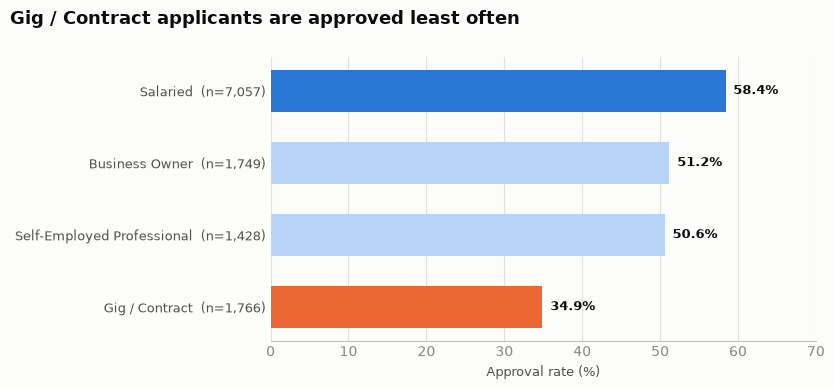

In [9]:
by_employment = (df.groupby("employment_type")
                   .agg(applications=("approved", "size"), approval_rate=("approved", "mean"))
                   .sort_values("approval_rate"))
by_employment["approval_rate"] = (by_employment["approval_rate"] * 100).round(1)
print(by_employment)
print("\nMedian monthly income by employment type:")
print(df.groupby("employment_type")["monthly_income"].median().round(0).to_string())

fig, ax = plt.subplots(figsize=(8.4, 4.0))
bars = ax.barh(range(len(by_employment)), by_employment["approval_rate"],
               color=[ORANGE, PALE, PALE, BLUE], height=0.58, zorder=3)
for bar, value in zip(bars, by_employment["approval_rate"]):
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2, f"{value:.1f}%",
            va="center", fontsize=9, color=INK, fontweight="bold")
ax.set_yticks(range(len(by_employment)))
ax.set_yticklabels([f"{i}  (n={int(n):,})" for i, n in
                    zip(by_employment.index, by_employment["applications"])],
                   fontsize=9, color=INK2)
style_axes(ax, horizontal=True)
ax.set_xlim(0, 70)
ax.set_xlabel("Approval rate (%)", color=INK2, fontsize=9)
plt.tight_layout(rect=[0, 0, 1, 0.88])
fig.text(0.012, 0.96, "Gig / Contract applicants are approved least often",
         fontsize=13, fontweight="bold", color=INK, ha="left", va="top")
plt.show()

### Employment type: a 23.5-point spread

Salaried applicants are approved 58.4% of the time, Gig/Contract applicants only **34.9%**.

The label itself is not the cause. Gig and contract applicants have a **median income of ₹28,000 against ₹50,000 for salaried applicants**, plus shorter job tenure and less verifiable earnings — so the same loan produces a much higher FOIR for them. Employment type is acting as a proxy for income stability.

This matters twice: it explains the coefficient we will see in Step 5.4, and it turns out to explain most of the gender gap in Step 5.6.

In [10]:
# Two further cuts: delinquencies (strong) and city tier (no signal)
by_delinq = (df.groupby("delinquencies_24m")
               .agg(applications=("approved", "size"), approval_rate=("approved", "mean")))
by_delinq["approval_rate"] = (by_delinq["approval_rate"] * 100).round(1)
print("Approval by delinquencies in last 24 months:")
print(by_delinq.head(6))

by_tier = (df.groupby("city_tier")
             .agg(applications=("approved", "size"), approval_rate=("approved", "mean")))
by_tier["approval_rate"] = (by_tier["approval_rate"] * 100).round(1)
print("\nApproval by city tier:")
print(by_tier)

Approval by delinquencies in last 24 months:
                   applications  approval_rate
delinquencies_24m                             
0                          7193           69.7
1                          2349           41.5
2                          1288           23.8
3                           649            7.4
4                           301            3.0
5                           137            1.5

Approval by city tier:
           applications  approval_rate
city_tier                             
1                  5709           53.2
2                  4087           52.5
3                  2204           53.0


**Repayment history is the third strong driver.** A single missed payment in 24 months costs 28 points of approval probability (69.7% → 41.5%); three or more is effectively an automatic decline (7.4%).

**City tier carries almost no signal** — 53.2% / 52.5% / 53.0% across tiers 1/2/3. It is kept as a feature because the brief specifies it, but we should not expect it to contribute, and in Step 5.4 its coefficient is indeed the smallest of the numeric features. Checking something and finding it does not matter is a result worth recording.

**So the credit team's working policy is: credit score ≥ 650, clean recent repayment history, and stable verifiable income.** Step 5.3 adds the missing piece — affordability.

---

# Step 5.3 — Engineer the affordability features

*Section owner: Mohammed Saalif Udyawar — Insights Analyst*

Nothing in the raw file measures **affordability** — whether the applicant can actually carry the new EMI alongside what they already pay. Indian lenders measure this with the **Fixed Obligation to Income Ratio (FOIR)**:

$$\text{FOIR} = \frac{\text{existing EMI} + \text{proposed EMI}}{\text{monthly income}}$$

A FOIR of 0.60 means 60% of the applicant's income would go to loan repayments. It has to be constructed, and it turns out to be the single strongest predictor in the dataset.

Two further features: **loan-to-income** (loan size relative to annual income) and the **new-to-credit flag** already built in Step 5.1.

In [11]:
df["foir"]           = (df["existing_emi"] + df["proposed_emi"]) / df["monthly_income"]
df["loan_to_income"] = df["loan_amount"] / (df["monthly_income"] * 12)
# df["is_ntc"] was created in Step 5.1, before credit_score is filled in Step 5.4

print(df[["foir", "loan_to_income"]].describe().round(3))
print(f"\nApplications with FOIR above 1.0 (EMIs exceed income): {(df['foir'] > 1).sum()}")
print(f"  ... of which approved: {df.loc[df['foir'] > 1, 'approved'].mean():.1%}")

            foir  loan_to_income
count  12000.000       12000.000
mean       0.358           0.531
std        0.207           0.225
min        0.005           0.015
25%        0.214           0.346
50%        0.317           0.519
75%        0.450           0.699
max        3.393           2.778

Applications with FOIR above 1.0 (EMIs exceed income): 139
  ... of which approved: 18.7%


A sanity check on the engineered feature before trusting it: **139 applications have a FOIR above 1.0**, meaning combined EMIs would exceed the applicant's entire monthly income, with a maximum of 3.39.

These survive the ÷12 income correction from Step 5.1, so they are not the data-entry artefact — they are genuine applications from people asking for more than they can afford, and **18.7% of them were still approved**. They are kept.

           applications  approval_rate
foir_band                             
<30%               5491           65.5
30-40%             2497           59.0
40-50%             1766           47.8
50-55%              531           32.4
>55%               1715           15.6


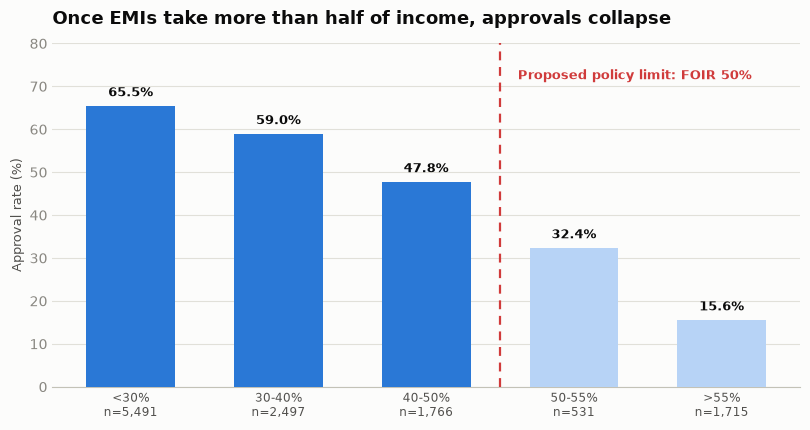

In [12]:
FOIR_LABELS = ["<30%", "30-40%", "40-50%", "50-55%", ">55%"]
df["foir_band"] = pd.cut(df["foir"], bins=[0, 0.30, 0.40, 0.50, 0.55, np.inf],
                         labels=FOIR_LABELS, right=False)

by_foir = (df.groupby("foir_band", observed=False)
             .agg(applications=("approved", "size"), approval_rate=("approved", "mean")))
by_foir["approval_rate"] = (by_foir["approval_rate"] * 100).round(1)
print(by_foir)

fig, ax = plt.subplots(figsize=(8.2, 4.4))
bars = ax.bar(range(len(by_foir)), by_foir["approval_rate"],
              color=[BLUE, BLUE, BLUE, PALE, PALE], width=0.6, zorder=3)
label_bars(ax, bars, by_foir["approval_rate"].values)
ax.set_xticks(range(len(by_foir)))
ax.set_xticklabels([f"{i}\nn={int(n):,}" for i, n in
                    zip(by_foir.index, by_foir["applications"])], fontsize=8.5, color=INK2)
style_axes(ax, "Approval rate (%)", 80)
ax.axvline(2.5, color=RED, lw=1.6, ls=(0, (4, 3)), zorder=4)
ax.text(2.62, 74, "Proposed policy limit: FOIR 50%", color=RED, fontsize=9.5,
        fontweight="bold", va="top")
ax.set_title("Once EMIs take more than half of income, approvals collapse",
             fontsize=13, fontweight="bold", color=INK, loc="left", pad=14)
plt.tight_layout()
plt.show()

### Approvals fall off a cliff past 50% FOIR

The decline is gentle up to 50% — 65.5% → 59.0% → 47.8%, about six points per band. Then it collapses: **47.8% → 32.4% → 15.6%**. Approval more than halves between the 40–50% band and the 50–55% band.

**Written as credit policy:** I would propose a **FOIR limit of 50%**, with **50–55% as a referral band** requiring explicit justification, and **above 55% a decline** unless there is a documented reason. That is what the bank's own historical decisions already support — this is not a new rule, it is the existing unwritten one made explicit.

In [13]:
lti_quartiles = pd.qcut(df["loan_to_income"], 4)
by_lti = (df.groupby(lti_quartiles, observed=False)
            .agg(applications=("approved", "size"), approval_rate=("approved", "mean")))
by_lti["approval_rate"] = (by_lti["approval_rate"] * 100).round(1)
print("Approval rate by loan-to-income quartile:")
print(by_lti)

Approval rate by loan-to-income quartile:
                 applications  approval_rate
loan_to_income                              
(0.0137, 0.346]          3000           61.5
(0.346, 0.519]           3002           57.3
(0.519, 0.699]           3000           50.3
(0.699, 2.778]           2998           42.7


### Loan-to-income is directionally right but much weaker

A clean monotonic decline, 61.5% → 42.7% — but a 19-point spread against FOIR's 50-point spread.

**FOIR is the better affordability measure** for two reasons: it accounts for debt the applicant is *already* carrying, and it reflects that a long tenure turns a large loan into a manageable EMI. Loan-to-income ignores both.

Worth remembering when the model reports a **negative** coefficient for loan-to-income in Step 5.4 — this table is the honest relationship, and the sign flip there is a statistical artefact, not a finding.

---

# Step 5.4 — Build the logistic regression pre-screener

*Section owner: Mulla Javeed — Model Builder*

**The target is `Declined = 1`.** The use case is about auto-declining, so the positive class should be the action being taken. This makes `predict_proba[:, 1]` the model's confidence that an application *should be declined* — which is exactly what the threshold in Step 5.5 operates on.

**Excluded from the features, and why:**

| Excluded | Reason |
|---|---|
| `application_id`, `application_date` | Identifiers — no predictive meaning |
| `city` | High cardinality; `city_tier` already carries the geography |
| `gender` | **Policy.** A bank cannot defend a credit decision that uses it. Revisited in Step 5.6 |
| `decision` | This is the target — including it would be leakage |
| `credit_history_months` | Perfectly collinear with `is_ntc` at zero; outside the brief's feature list |

**On scaling.** The brief says to scale *the numeric features*, so that is what we do — the one-hot dummies stay on their natural 0/1 scale. This matters for how the coefficients read. A scaled numeric coefficient is the effect of **one standard deviation** of that variable; an unscaled dummy coefficient is the effect of **being in that category at all**. The two are therefore comparable *within* their own group but not across groups, and we interpret them that way in the table below.

In [14]:
# Target: predicting DECLINES
df["target"] = (df["decision"] == "Declined").astype(int)

model_df = df.copy()

# Fill blank credit scores with the median - is_ntc (built in Step 5.1) tells the model which
median_score = model_df["credit_score"].median()
model_df["credit_score"] = model_df["credit_score"].fillna(median_score)
print(f"Median credit score used to fill new-to-credit applicants: {median_score:.0f}")

NUMERIC_FEATURES = ["credit_score", "is_ntc", "foir", "loan_to_income", "delinquencies_24m",
                    "num_active_loans", "years_in_current_job", "age", "tenure_months", "city_tier"]
CATEGORICAL_FEATURES = ["employment_type", "loan_purpose"]

X = pd.get_dummies(model_df[NUMERIC_FEATURES + CATEGORICAL_FEATURES],
                   columns=CATEGORICAL_FEATURES, drop_first=True).astype(float)
y = model_df["target"]

# Leakage check - these must NOT appear
leaks = [c for c in X.columns if any(k in c.lower() for k in
         ["gender", "decision", "application_id", "city_tier_", "approved"])]
print(f"Leakage check - forbidden columns present: {leaks if leaks else 'none'}")
print(f"Feature matrix: {X.shape[0]:,} rows x {X.shape[1]} features")
print(f"Features: {list(X.columns)}")

Median credit score used to fill new-to-credit applicants: 726
Leakage check - forbidden columns present: none
Feature matrix: 12,000 rows x 19 features
Features: ['credit_score', 'is_ntc', 'foir', 'loan_to_income', 'delinquencies_24m', 'num_active_loans', 'years_in_current_job', 'age', 'tenure_months', 'city_tier', 'employment_type_Gig / Contract', 'employment_type_Salaried', 'employment_type_Self-Employed Professional', 'loan_purpose_Debt Consolidation', 'loan_purpose_Education', 'loan_purpose_Home Renovation', 'loan_purpose_Medical', 'loan_purpose_Travel', 'loan_purpose_Wedding']


In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

# Scale the NUMERIC features only, as the brief specifies - the one-hot dummies are already
# on a 0/1 scale and standardising them would make their coefficients read as "one standard
# deviation of a dummy", which is not a quantity anyone can picture.
#
# The scaler is fitted on the TRAINING set only. Fitting it on all 12,000 rows would let the
# test set's mean and standard deviation leak into training.
scaler = StandardScaler().fit(X_train[NUMERIC_FEATURES])

X_train_scaled = X_train.copy()
X_test_scaled  = X_test.copy()
X_train_scaled[NUMERIC_FEATURES] = scaler.transform(X_train[NUMERIC_FEATURES])
X_test_scaled[NUMERIC_FEATURES]  = scaler.transform(X_test[NUMERIC_FEATURES])

model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
model.fit(X_train_scaled, y_train)

y_pred  = model.predict(X_test_scaled)
y_proba = model.predict_proba(X_test_scaled)[:, 1]   # P(Declined)

print(f"Training set: {len(X_train):,}   Test set: {len(X_test):,}")
print(f"\nAccuracy           : {accuracy_score(y_test, y_pred):.1%}")
print(f"ROC-AUC            : {roc_auc_score(y_test, y_proba):.3f}")
print(f"Precision (Declined): {precision_score(y_test, y_pred):.1%}")
print(f"Recall (Declined)   : {recall_score(y_test, y_pred):.1%}")
print("\n" + classification_report(y_test, y_pred,
                                   target_names=["Approved (0)", "Declined (1)"], digits=3))

Training set: 9,600   Test set: 2,400

Accuracy           : 79.1%
ROC-AUC            : 0.867
Precision (Declined): 79.1%
Recall (Declined)   : 75.5%

              precision    recall  f1-score   support

Approved (0)      0.791     0.823     0.806      1271
Declined (1)      0.791     0.755     0.772      1129

    accuracy                          0.791      2400
   macro avg      0.791     0.789     0.789      2400
weighted avg      0.791     0.791     0.790      2400



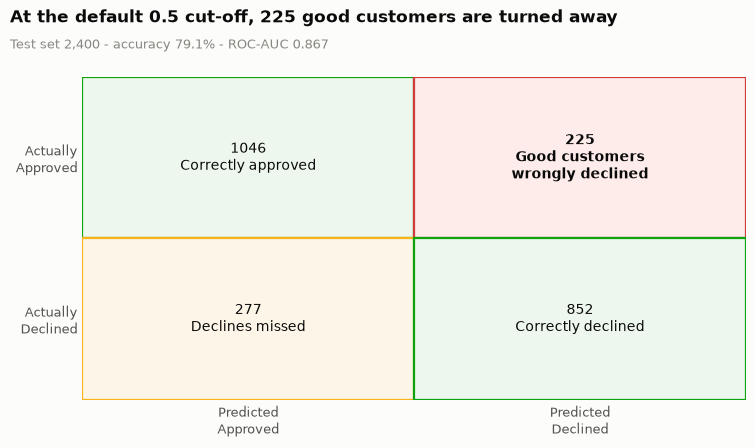


False positives: 225 of 1271 good applications = 17.7% of creditworthy applicants wrongly declined at 0.5


In [16]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(7.6, 4.6))
cells = [[f"{tn}\nCorrectly approved", f"{fp}\nGood customers\nwrongly declined"],
         [f"{fn}\nDeclines missed",    f"{tp}\nCorrectly declined"]]
fills = [["#eef7ee", "#fdecea"], ["#fdf6e8", "#eef7ee"]]
edges = [["#0ca30c", RED],       ["#fab219", "#0ca30c"]]

for i in range(2):
    for j in range(2):
        ax.add_patch(plt.Rectangle((j, 1 - i), 1, 1, fc=fills[i][j], ec=edges[i][j], lw=1.6, zorder=2))
        ax.text(j + .5, 1 - i + .5, cells[i][j], ha="center", va="center", fontsize=10,
                color=INK, fontweight="bold" if (i, j) == (0, 1) else "normal", zorder=3)

ax.set_xlim(0, 2); ax.set_ylim(0, 2)
ax.set_xticks([.5, 1.5]); ax.set_xticklabels(["Predicted\nApproved", "Predicted\nDeclined"],
                                             fontsize=9.5, color=INK2)
ax.set_yticks([1.5, .5]); ax.set_yticklabels(["Actually\nApproved", "Actually\nDeclined"],
                                             fontsize=9.5, color=INK2)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(length=0)
plt.tight_layout(rect=[0, 0, 1, 0.85])
fig.text(0.012, 0.965, f"At the default 0.5 cut-off, {fp} good customers are turned away",
         fontsize=12.5, fontweight="bold", color=INK, ha="left", va="top")
fig.text(0.012, 0.900, f"Test set {len(y_test):,} - accuracy {accuracy_score(y_test, y_pred):.1%}"
                       f" - ROC-AUC {roc_auc_score(y_test, y_proba):.3f}",
         fontsize=9, color=MUTED, ha="left", va="top")
plt.show()

good_customers = (y_test == 0).sum()
print(f"\nFalse positives: {fp} of {good_customers} good applications = "
      f"{fp / good_customers:.1%} of creditworthy applicants wrongly declined at 0.5")

### The confusion matrix in business language

- **225 false positives.** At the default 0.5 cut-off, **225 applicants the credit team would have approved are turned away by the machine** — that is 17.7% of every good application in the test set. Scaled to 3,000 applications a month, roughly **280 creditworthy customers a month refused without a human ever reading their file.**
- **277 false negatives.** 277 applications the team would have declined still reach an analyst. This is the *cheap* error — it costs 25 minutes, not a customer.

**The two errors are not symmetric, and that asymmetry is the entire use case.** A false negative wastes some analyst time; a false positive loses a customer, their lifetime value, and potentially a complaint the bank cannot defend. That is why the default cut-off is unusable and why Step 5.5 exists.

> "The model is 79% accurate" describes the model. **"At the default cut-off, 225 applicants the bank would have approved are wrongly declined"** is what the Credit Policy Analyst needs to hear.

In [17]:
# Where does the model succeed, and where does it fail?
test_ntc = model_df.loc[X_test.index, "is_ntc"]

acc_scored = accuracy_score(y_test[test_ntc == 0], y_pred[test_ntc.values == 0])
acc_ntc    = accuracy_score(y_test[test_ntc == 1], y_pred[test_ntc.values == 1])

print(f"Accuracy on scored applicants      : {acc_scored:.1%}  (n={(test_ntc == 0).sum():,})")
print(f"Accuracy on new-to-credit applicants: {acc_ntc:.1%}  (n={(test_ntc == 1).sum():,})")

print("\nWhy - what the model can actually see for NTC applicants:")
ntc_rows = df[df["is_ntc"] == 1]
print(f"  delinquencies_24m unique values : {ntc_rows['delinquencies_24m'].unique()}")
print(f"  num_active_loans unique values  : {sorted(ntc_rows['num_active_loans'].unique())}")
print(f"  existing_emi maximum            : {ntc_rows['existing_emi'].max():.0f}")

Accuracy on scored applicants      : 81.2%  (n=2,197)
Accuracy on new-to-credit applicants: 56.7%  (n=203)

Why - what the model can actually see for NTC applicants:
  delinquencies_24m unique values : [0]
  num_active_loans unique values  : [np.int64(0)]
  existing_emi maximum            : 0


### The number that matters more than accuracy: 81.2% vs 56.7%

The model is **81.2% accurate on applicants with a credit score and 56.7% on new-to-credit applicants** — barely better than a coin toss for the latter.

The cause is **structural, not statistical.** For all 1,039 NTC applicants, `delinquencies_24m` is 0, `num_active_loans` is 0 and `existing_emi` is 0 — necessarily, because someone who has never borrowed has no loans to be late on. Their `credit_score` is an imputed median. **Three of the model's four strongest features carry no information at all about this group**, and FOIR only works off the proposed EMI.

No amount of modelling fixes this; the signal is not in the data. The bank would need something else — bank-statement cash flow, rent or utility payment history, employer verification.

**This is the group the pre-screener must not be allowed to decide for.** It drives the design recommendation in Step 5.5 and the caveat in Step 5.7.

In [18]:
coefficients = (pd.Series(model.coef_[0], index=X.columns)
                  .sort_values(key=abs, ascending=False))
print("All coefficients (positive = pushes towards DECLINE; numerics scaled, flags not):")
print(coefficients.round(3).to_string())
print(f"\nIntercept: {model.intercept_[0]:.4f}")
print("\n--- Five largest by magnitude ---")
print(coefficients.head(5).round(3).to_string())

All coefficients (positive = pushes towards DECLINE; numerics scaled, flags not):
foir                                          1.220
credit_score                                 -1.009
delinquencies_24m                             0.980
employment_type_Gig / Contract                0.639
loan_purpose_Debt Consolidation               0.509
employment_type_Salaried                     -0.420
is_ntc                                        0.381
loan_purpose_Wedding                          0.209
loan_to_income                               -0.195
loan_purpose_Travel                           0.185
years_in_current_job                         -0.146
loan_purpose_Home Renovation                  0.121
loan_purpose_Medical                          0.118
num_active_loans                              0.110
tenure_months                                 0.087
age                                          -0.045
loan_purpose_Education                        0.019
employment_type_Self-Employed Prof

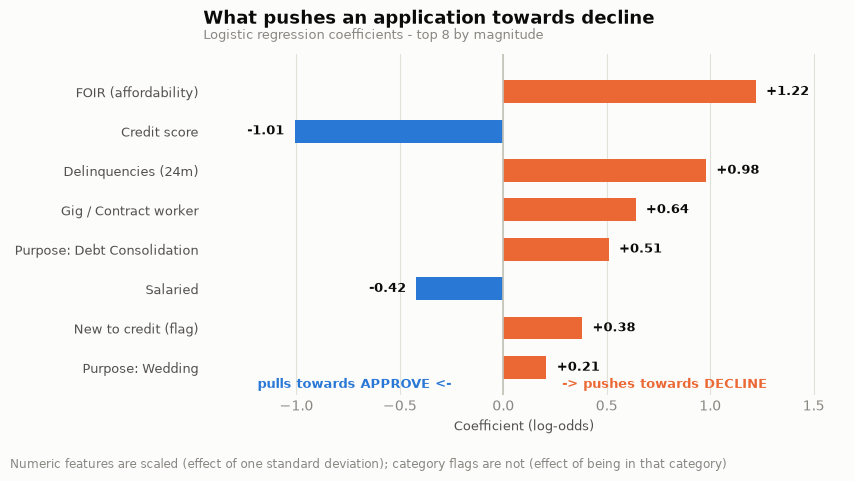

In [19]:
top = coefficients.head(8)[::-1]
LABELS = {"foir": "FOIR (affordability)", "credit_score": "Credit score",
          "delinquencies_24m": "Delinquencies (24m)", "is_ntc": "New to credit (flag)",
          "employment_type_Gig / Contract": "Gig / Contract worker",
          "employment_type_Salaried": "Salaried",
          "loan_purpose_Debt Consolidation": "Purpose: Debt Consolidation",
          "loan_purpose_Wedding": "Purpose: Wedding",
          "loan_purpose_Travel": "Purpose: Travel",
          "loan_to_income": "Loan-to-income"}

fig, ax = plt.subplots(figsize=(8.6, 4.8))
bars = ax.barh(range(len(top)), top.values,
               color=[ORANGE if v > 0 else BLUE for v in top.values], height=0.58, zorder=3)
for bar, value in zip(bars, top.values):
    ax.text(value + (0.05 if value > 0 else -0.05), bar.get_y() + bar.get_height() / 2,
            f"{value:+.2f}", va="center", ha="left" if value > 0 else "right",
            fontsize=9, color=INK, fontweight="bold")
ax.set_yticks(range(len(top)))
ax.set_yticklabels([LABELS.get(i, i) for i in top.index], fontsize=9.5, color=INK2)
ax.axvline(0, color=BASE, lw=1.2, zorder=4)
for side in ("top", "right", "left", "bottom"):
    ax.spines[side].set_visible(False)
ax.xaxis.grid(True, color=GRID, lw=0.8); ax.set_axisbelow(True); ax.tick_params(length=0)
ax.set_xlim(-1.45, 1.65); ax.set_ylim(-0.7, len(top) - 0.05)
ax.set_xlabel("Coefficient (log-odds)", color=INK2, fontsize=9)
ax.text(0.78, -0.52, "-> pushes towards DECLINE", color=ORANGE, fontsize=9,
        fontweight="bold", ha="center")
ax.text(-0.72, -0.52, "pulls towards APPROVE <-", color=BLUE, fontsize=9,
        fontweight="bold", ha="center")
ax.set_title("What pushes an application towards decline",
             fontsize=13, fontweight="bold", color=INK, loc="left", pad=22)
ax.text(0, 1.045, "Logistic regression coefficients - top 8 by magnitude",
        transform=ax.transAxes, fontsize=9, color=MUTED)
plt.tight_layout(rect=[0, 0.055, 1, 1])
fig.text(0.012, 0.014, "Numeric features are scaled (effect of one standard deviation); "
                       "category flags are not (effect of being in that category)",
         fontsize=8.5, color=MUTED)
plt.show()

### Reading the coefficients like a credit analyst

Positive pushes an application **towards decline**, negative **towards approval**.

Two different units sit in this list, and mixing them up is the easiest mistake to make here. The numeric features are scaled, so their coefficients are the effect of **one standard deviation**. The category flags are not scaled, so theirs are the effect of **being in that category** rather than in the reference category (Business Owner for employment type, Business purpose for loan purpose). Compare numbers within a group, not across groups.

**The five largest coefficients, as the brief asks for:**

| Feature | Coefficient | What it means for an applicant |
|---|---|---|
| **FOIR** | **+1.22** | The strongest signal in the model. One standard deviation more of their income already committed to EMIs is the single hardest push towards decline. |
| **Credit score** | **−1.01** | Almost equally strong in the other direction — a higher bureau score pulls an application towards approval. |
| **Delinquencies (24m)** | **+0.98** | **Every additional missed payment pushes the application towards decline**, roughly as hard as a full standard deviation of FOIR. |
| **Gig / Contract** | **+0.64** | Being a gig or contract worker rather than a business owner is itself a push towards decline. |
| **Purpose: Debt Consolidation** | **+0.51** | Borrowing to consolidate existing debt reads as a stress signal, not a neutral purpose. |

Just below them: **Salaried −0.42** (a salaried job pulls towards approval) and **new to credit +0.38** (having no credit history is a mild push towards decline — the model has learned the bank is warier without a score).

Everything from `years_in_current_job` (−0.15) downwards is small, and `city_tier` at **+0.02** is effectively zero — the same non-result found independently in Step 5.2.

### The check that shows the model learned real policy

The three largest coefficients are **FOIR, credit score and delinquencies** — the same three drivers found independently in Steps 5.2 and 5.3, in the same order of importance. The model was never told about the 650 cliff or the 50% FOIR cliff; it rediscovered both from the data.

That is the strongest available evidence that it learned the bank's actual credit policy rather than an artefact of the sample, and it is what makes the model defensible to the credit team.

### One coefficient we will not interpret

**`loan_to_income` comes out at −0.195**, which would read as "larger loans relative to income push towards approval." That is false — Step 5.3 showed approval falling from 61.5% to 42.7% across its quartiles.

The sign flips because of collinearity: loan-to-income correlates with FOIR (r ≈ 0.54), with `loan_amount` and with `monthly_income` (r ≈ 0.74). Once FOIR is in the model holding affordability constant, the residual variation in loan-to-income picks up something else — largely the fact that bigger loans go to higher earners.

**A coefficient in a multivariate model is conditional on every other feature in it, not a statement about an applicant.** We report the five stable features above and flag this one rather than explaining it away. If the bank wanted a defensible loan-size rule, the univariate table in Step 5.3 is the honest basis for it, not this coefficient.

---

# Step 5.5 — Set the auto-decline threshold

*Section owner: Mulla Javeed — Model Builder*

A logistic regression does not output a decision, it outputs a **probability**. Turning that into an action requires a cut-off, and `predict()` silently uses 0.5 — a statistical default with nothing to do with the bank's appetite for risk.

At 0.5 this model auto-declines 44.9% of applications, and **one in five of those is someone the credit team approved.** No lending unit would sign that off.

So the bank states its risk limit instead, and the model's only job is to show where that limit falls:

> **No more than 5% of auto-declined applications may be ones the credit team would have approved.**

In [20]:
THRESHOLDS = [0.50, 0.60, 0.70, 0.80, 0.85, 0.88, 0.90, 0.92, 0.95]
total_declines = (y_test == 1).sum()

rows = []
for t in THRESHOLDS:
    auto = y_proba >= t
    n_auto = auto.sum()
    n_wrong = (y_test.values[auto] == 0).sum()
    rows.append({
        "threshold": t,
        "pct_auto_declined": round(n_auto / len(y_test) * 100, 1),
        "n_auto_declined": n_auto,
        "pct_wrongly_declined": round(n_wrong / n_auto * 100, 1) if n_auto else 0.0,
        "n_wrongly_declined": n_wrong,
        "pct_declines_caught": round((y_test.values[auto] == 1).sum() / total_declines * 100, 1),
    })

threshold_table = pd.DataFrame(rows)
threshold_table["meets_5pct_rule"] = np.where(
    threshold_table["pct_wrongly_declined"] <= 5.0, "YES", "no")
print(threshold_table.to_string(index=False))

within_rule = threshold_table[threshold_table["pct_wrongly_declined"] <= 5.0]
chosen = within_rule.iloc[0]
CHOSEN_THRESHOLD = chosen["threshold"]
print(f"\nLowest threshold meeting the 5% rule: {CHOSEN_THRESHOLD:.2f}")
print(f"  auto-declines {chosen['pct_auto_declined']}% of applications")
print(f"  of which {chosen['pct_wrongly_declined']}% were actually approved by the credit team")

 threshold  pct_auto_declined  n_auto_declined  pct_wrongly_declined  n_wrongly_declined  pct_declines_caught meets_5pct_rule
      0.50               44.9             1077                  20.9                 225                 75.5              no
      0.60               37.6              903                  16.8                 152                 66.5              no
      0.70               30.8              739                  12.0                  89                 57.6              no
      0.80               23.4              562                   7.1                  40                 46.2              no
      0.85               19.7              472                   5.9                  28                 39.3              no
      0.88               16.9              406                   5.4                  22                 34.0              no
      0.90               15.2              364                   4.7                  17                 30.7         

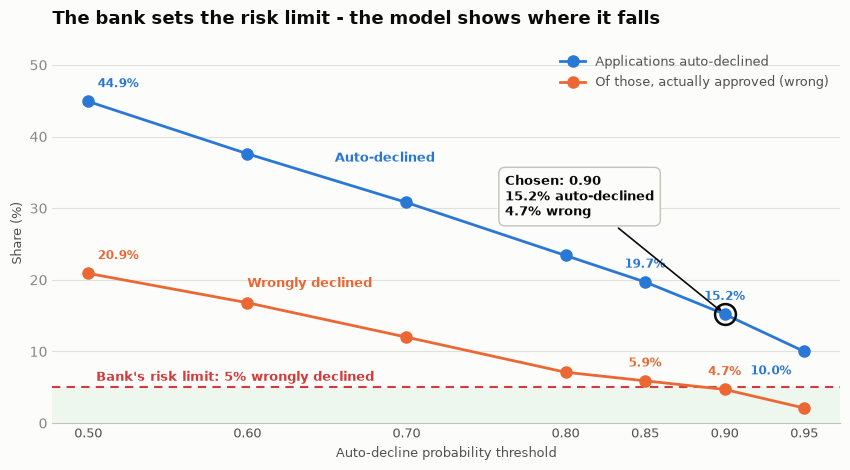

In [21]:
plot_rows = threshold_table[threshold_table["threshold"].isin([0.5, 0.6, 0.7, 0.8, 0.85, 0.90, 0.95])]
ths   = plot_rows["threshold"].values
auto  = plot_rows["pct_auto_declined"].values
wrong = plot_rows["pct_wrongly_declined"].values

fig, ax = plt.subplots(figsize=(8.6, 4.8))
ax.axhspan(0, 5, color="#eef7ee", zorder=1)
ax.axhline(5, color=RED, lw=1.5, ls=(0, (4, 3)), zorder=4)
ax.text(0.505, 5.9, "Bank's risk limit: 5% wrongly declined", color=RED,
        fontsize=9, fontweight="bold")

ax.plot(ths, auto,  color=BLUE,   lw=2, marker="o", ms=8, zorder=5,
        label="Applications auto-declined")
ax.plot(ths, wrong, color=ORANGE, lw=2, marker="o", ms=8, zorder=5,
        label="Of those, actually approved (wrong)")
ax.text(0.655, 36.5, "Auto-declined", color=BLUE, fontsize=9.5, fontweight="bold")
ax.text(0.60, 19.0, "Wrongly declined", color=ORANGE, fontsize=9.5, fontweight="bold")

for t, a, w in zip(ths, auto, wrong):
    if t in (0.5, 0.85, 0.90, 0.95):
        ha = "left" if t == 0.5 else ("right" if t == 0.95 else "center")
        dx = 0.006 if t == 0.5 else (-0.008 if t == 0.95 else 0)
        ax.text(t + dx, a + (-3.2 if t == 0.95 else 2.0), f"{a:.1f}%", ha=ha,
                fontsize=8.5, color=BLUE, fontweight="bold")
        if t != 0.95:
            ax.text(t + dx, w + 2.0, f"{w:.1f}%", ha=ha, fontsize=8.5,
                    color=ORANGE, fontweight="bold")

chosen_auto = float(chosen["pct_auto_declined"])
ax.plot([CHOSEN_THRESHOLD], [chosen_auto], "o", ms=15, mfc="none", mec=INK, mew=1.8, zorder=6)
ax.annotate(f"Chosen: {CHOSEN_THRESHOLD:.2f}\n{chosen_auto}% auto-declined\n"
            f"{chosen['pct_wrongly_declined']}% wrong",
            xy=(CHOSEN_THRESHOLD, chosen_auto), xytext=(0.762, 29),
            fontsize=9, color=INK, fontweight="bold",
            arrowprops=dict(arrowstyle="-|>", color=INK, lw=1.2),
            bbox=dict(fc="#fcfcfb", ec=BASE, boxstyle="round,pad=0.5"))

style_axes(ax, "Share (%)", 53)
ax.set_xlabel("Auto-decline probability threshold", color=INK2, fontsize=9)
ax.set_xticks(ths); ax.set_xticklabels([f"{t:.2f}" for t in ths], fontsize=9, color=INK2)
ax.legend(frameon=False, loc="upper right", fontsize=9, labelcolor=INK2)
ax.set_title("The bank sets the risk limit - the model shows where it falls",
             fontsize=13, fontweight="bold", color=INK, loc="left", pad=14)
plt.tight_layout()
plt.show()

### Chosen threshold: 0.90

It is the **lowest** threshold that stays inside the 5% rule, and lowest is what we want — every step above it buys safety the bank has already said it does not need, and pays for that safety in volume.

- **0.85** auto-declines more (19.7%) but **5.9% of those are wrong — it breaks the rule.**
- **0.88** is closer at 5.4%, and still breaks it. Worth checking rather than assuming.
- **0.95** is comfortably safe at 2.1% but only removes 10% of applications — about 110 fewer applications a month than 0.90, for safety already paid for.

In [22]:
MONTHLY_APPLICATIONS = 3000
MINUTES_PER_REVIEW   = 25

pct = float(chosen["pct_auto_declined"]) / 100
apps_per_month  = MONTHLY_APPLICATIONS * pct
hours_per_month = apps_per_month * MINUTES_PER_REVIEW / 60
wrong_per_month = apps_per_month * float(chosen["pct_wrongly_declined"]) / 100
total_hours     = MONTHLY_APPLICATIONS * MINUTES_PER_REVIEW / 60

print(f"THE BUSINESS CASE AT A {CHOSEN_THRESHOLD:.2f} THRESHOLD")
print("=" * 52)
print(f"Applications auto-declined   : {pct:.1%}")
print(f"Applications per month       : {apps_per_month:,.0f} of {MONTHLY_APPLICATIONS:,}")
print(f"Analyst hours freed per month: {hours_per_month:,.0f} of {total_hours:,.0f} "
      f"({hours_per_month / total_hours:.0%} of the review load)")
print(f"Wrongly declined per month   : {wrong_per_month:,.0f} applications "
      f"({chosen['pct_wrongly_declined']}% of auto-declines)")
print(f"Share of all declines caught : {chosen['pct_declines_caught']}%")

THE BUSINESS CASE AT A 0.90 THRESHOLD
Applications auto-declined   : 15.2%
Applications per month       : 456 of 3,000
Analyst hours freed per month: 190 of 1,250 (15% of the review load)
Wrongly declined per month   : 21 applications (4.7% of auto-declines)
Share of all declines caught : 30.7%


### What a 0.90 threshold is worth every month

| | |
|---|---|
| Applications auto-declined | **15.2%** |
| Monthly volume | **≈ 456 applications** of 3,000 |
| Analyst time freed | **≈ 190 hours/month** — about 15% of the unit's 1,250-hour load, or one full-time analyst |
| Wrongly declined | ≈ 21 applications/month (4.7% of auto-declines) |
| Share of all declines caught | 30.7% |

**Why the number is modest, and why that is the right answer.** A single auto-decline lane at a strict risk limit catches only about 31% of declines; the other 69% still reach an analyst. That is not a weakness — it is the price of the 5% rule, and the bank chose it. **190 hours a month at near-zero risk is a defensible first step**, and once repayment outcomes start coming back the limit can be revisited with evidence rather than caution.

**The honest comparison.** A single rule — `credit_score < 650` — would flag 9.8% of applications with only 3.0% wrongly declined, with no model at all. The model adds about **5 percentage points of extra volume** (15.2% vs 9.8%), worth roughly 160 applications and 67 analyst hours a month, from cases where FOIR and delinquencies justify a decline that the score alone would not. That is a real gain, and it is the answer to the obvious question from the Head of Retail Lending: *"why not just set a score floor?"*

In [23]:
# Sanity check on that comparison: what does a plain score floor achieve?
score_floor = df["credit_score"] < 650
print(f"Rule 'credit_score < 650' alone:")
print(f"  flags {score_floor.sum():,} applications ({score_floor.mean():.1%})")
print(f"  of which {df.loc[score_floor, 'approved'].mean():.1%} were actually approved (wrong)")
print(f"\nModel at {CHOSEN_THRESHOLD:.2f}: {chosen['pct_auto_declined']}% auto-declined, "
      f"{chosen['pct_wrongly_declined']}% wrong")

Rule 'credit_score < 650' alone:
  flags 1,179 applications (9.8%)
  of which 3.0% were actually approved (wrong)

Model at 0.90: 15.2% auto-declined, 4.7% wrong


---

### A refinement: new-to-credit applicants should not be in the auto-decline lane

Step 5.4 established that the model is only 56.7% accurate on new-to-credit applicants, for structural reasons. That weakness does not disappear just because the threshold is high — so it is worth checking **who is actually inside the auto-decline lane at 0.90.**

In [24]:
test_view = df.loc[X_test.index].copy()
test_view["prob"] = y_proba
test_view["actual_declined"] = y_test.values

print("Wrong-decline rate inside the auto-decline lane, split by credit history")
print("=" * 74)
print(f"{'thr':>5} {'auto':>6} {'wrong%':>7} | {'NTC auto':>9} {'NTC wrong%':>11} "
      f"| {'scored auto':>12} {'scored wrong%':>14}")
for t in [0.80, 0.85, 0.88, 0.90, 0.95]:
    auto = test_view["prob"] >= t
    ntc    = test_view[auto & (test_view["is_ntc"] == 1)]
    scored = test_view[auto & (test_view["is_ntc"] == 0)]
    ntc_wrong = (ntc["actual_declined"] == 0).mean() * 100 if len(ntc) else float("nan")
    print(f"{t:5.2f} {auto.sum():6d} {(test_view['actual_declined'][auto] == 0).mean() * 100:7.1f} "
          f"| {len(ntc):9d} {ntc_wrong:11.1f} "
          f"| {len(scored):12d} {(scored['actual_declined'] == 0).mean() * 100:14.1f}")

Wrong-decline rate inside the auto-decline lane, split by credit history
  thr   auto  wrong% |  NTC auto  NTC wrong% |  scored auto  scored wrong%
 0.80    562     7.1 |        21        33.3 |          541            6.1
 0.85    472     5.9 |        15        40.0 |          457            4.8
 0.88    406     5.4 |        12        50.0 |          394            4.1
 0.90    364     4.7 |        12        50.0 |          352            3.1
 0.95    240     2.1 |         3        33.3 |          237            1.7


**At 0.90, 12 of the 364 auto-declined applications are new-to-credit — and 6 of those 12 were applications the credit team had approved.** A 50% error rate inside that segment, against 3.1% for scored applicants. NTC applicants are 3.3% of the lane's volume and about a third of its errors.

**On the small sample:** 12 observations cannot establish that the true error rate is 50%, and we do not claim it does. But the structural argument stands on its own, and three independent lines of evidence agree — 56.7% accuracy on NTC applicants, the fact that `delinquencies_24m`, `num_active_loans` and `existing_emi` are **structurally zero** for all of them, and the AUC check below. The 50% is corroboration, not the argument.

In [25]:
# Independent check: how much signal is there for NTC applicants at all?
ntc_only = model_df[model_df["is_ntc"] == 1]
X_ntc = pd.get_dummies(
    ntc_only[["foir", "loan_to_income", "years_in_current_job", "age", "tenure_months",
              "city_tier", "monthly_income", "employment_type", "loan_purpose"]],
    columns=["employment_type", "loan_purpose"], drop_first=True).astype(float)
y_ntc = ntc_only["target"]

Xn_tr, Xn_te, yn_tr, yn_te = train_test_split(X_ntc, y_ntc, test_size=0.25,
                                              stratify=y_ntc, random_state=RANDOM_STATE)
sc_n = StandardScaler().fit(Xn_tr)
m_n = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(sc_n.transform(Xn_tr), yn_tr)
auc_ntc = roc_auc_score(yn_te, m_n.predict_proba(sc_n.transform(Xn_te))[:, 1])

print(f"AUC of a model trained on NTC applicants only : {auc_ntc:.3f}")
print(f"AUC of the main model on the full population  : {roc_auc_score(y_test, y_proba):.3f}")
print("\n-> The signal genuinely is not there. This is a data problem, not a modelling one.")

AUC of a model trained on NTC applicants only : 0.632
AUC of the main model on the full population  : 0.867

-> The signal genuinely is not there. This is a data problem, not a modelling one.


In [26]:
# DESIGN B - route every new-to-credit application to a human,
# auto-decline only applicants who have a credit score.
print("Design B: NTC always reviewed by an analyst; model auto-declines scored applicants only")
print("=" * 86)
print(f"{'thr':>5} | {'% of ALL apps auto-declined':>28} {'wrong%':>8} {'apps/mo':>9} {'hrs/mo':>8}")

# Design A's figures, to compare every Design B row against
a_pct   = float(chosen["pct_auto_declined"])
a_wrong = float(chosen["pct_wrongly_declined"])

lowest_in_rule = None   # lowest threshold that merely satisfies the 5% rule
dominates_a    = None   # lowest threshold that beats Design A on BOTH volume and error

for t in [0.70, 0.75, 0.80, 0.82, 0.85, 0.88, 0.90, 0.95]:
    auto = (test_view["prob"] >= t) & (test_view["is_ntc"] == 0)
    pct_b = auto.sum() / len(test_view) * 100
    wrong_b = (test_view["actual_declined"][auto] == 0).mean() * 100
    flag = ""
    if wrong_b <= 5.0 and lowest_in_rule is None:
        lowest_in_rule = (t, pct_b, wrong_b)
        flag += "  <-- lowest within the 5% rule"
    if wrong_b <= a_wrong and pct_b >= a_pct and dominates_a is None:
        dominates_a = (t, pct_b, wrong_b)
        flag += "  <-- RECOMMENDED: beats Design A on volume AND error"
    print(f"{t:5.2f} | {pct_b:28.1f} {wrong_b:8.1f} "
          f"{MONTHLY_APPLICATIONS * pct_b / 100:9.0f} "
          f"{MONTHLY_APPLICATIONS * pct_b / 100 * MINUTES_PER_REVIEW / 60:8.0f}{flag}")

print(f"\nLowest threshold inside the 5% rule : {lowest_in_rule[0]:.2f} "
      f"({lowest_in_rule[1]:.1f}% auto-declined, {lowest_in_rule[2]:.1f}% wrong)")
print(f"  -> only {5.0 - lowest_in_rule[2]:.1f} points of margin against the limit, so we do"
      f" not take it.")

# We recommend the threshold that is strictly better than Design A on both dimensions,
# because it needs no trade-off argument at all.
t_b, pct_b, wrong_b = dominates_a
apps_b  = MONTHLY_APPLICATIONS * pct_b / 100
hours_b = apps_b * MINUTES_PER_REVIEW / 60

print("\n" + "=" * 86)
print(f"{'':28} {'Design A':>14} {'Design B':>14}")
print(f"{'Threshold':28} {CHOSEN_THRESHOLD:>14.2f} {t_b:>14.2f}")
print(f"{'Applications auto-declined':28} {chosen['pct_auto_declined']:>13}% {pct_b:>13.1f}%")
print(f"{'Wrongly declined':28} {chosen['pct_wrongly_declined']:>13}% {wrong_b:>13.1f}%")
print(f"{'Applications per month':28} {apps_per_month:>14,.0f} {apps_b:>14,.0f}")
print(f"{'Analyst hours per month':28} {hours_per_month:>14,.0f} {hours_b:>14,.0f}")

Design B: NTC always reviewed by an analyst; model auto-declines scored applicants only
  thr |  % of ALL apps auto-declined   wrong%   apps/mo   hrs/mo
 0.70 |                         29.4     10.8       881      367
 0.75 |                         26.4      8.5       791      330
 0.80 |                         22.5      6.1       676      282
 0.82 |                         21.1      5.5       634      264
 0.85 |                         19.0      4.8       571      238  <-- lowest within the 5% rule
 0.88 |                         16.4      4.1       492      205  <-- RECOMMENDED: beats Design A on volume AND error
 0.90 |                         14.7      3.1       440      183
 0.95 |                          9.9      1.7       296      123

Lowest threshold inside the 5% rule : 0.85 (19.0% auto-declined, 4.8% wrong)
  -> only 0.2 points of margin against the limit, so we do not take it.

                                   Design A       Design B
Threshold                        

### Design A vs Design B

| | **Design A** — single lane | **Design B** — new-to-credit always sees a human |
|---|---|---|
| Threshold | 0.90 | **0.88** |
| Applications auto-declined | 15.2% | **16.4%** |
| Wrongly declined | 4.7% | **4.1%** |
| Applications per month | ~456 | **~492** |
| Analyst hours freed | ~190 | **~205** |

**More volume and less risk at the same time.** Removing the one segment the model cannot read lets us lower the threshold and still sit further inside the bank's limit than Design A does — about **36 more applications and 15 more analyst hours a month**, with the wrong-decline rate falling from 4.7% to 4.1%. There is no trade-off to argue about: Design B is better on both numbers at once, which is why we recommend 0.88 rather than the lowest threshold that merely passes the rule.

**Why not go lower still.** Design B technically satisfies the 5% rule all the way down to **0.85**, which would auto-decline 19.0% of applications — about 571 a month and 238 analyst hours. But its wrong-decline rate there is 4.8%, leaving only 0.2 points of margin against the bank's limit, and that limit is estimated from 2,400 test applications. One bad month of sampling variation puts it over. **We would not recommend a number whose safety depends on the sample being typical**, so 0.88 is where we stop.

It is also easier to defend. *"We never auto-decline someone with no credit history"* is a sentence the Head of Retail Lending, a regulator and a declined customer can all follow, and it is operationally trivial — a null check on one column before the model is even called.

**Recommendation: Design A (0.90) as the baseline, Design B (0.88) as the immediate refinement.**

### Caveats to state with the number

- The threshold is calibrated on 2,400 test applications, so the 4.7% carries sampling error. At ~456 auto-declines a month, expect month-to-month variation — **recalibrate quarterly**.
- The figure depends on the cleaning decisions in Step 5.1. Under different but defensible handling of those 453 rows, the recommended threshold moves between 0.85 and 0.90 — a spread of roughly 160 applications and 65 analyst hours a month. The cleaning log is the audit trail for this number.
- **"Wrong" here means the credit team would have approved, not that the customer would have repaid.** Both sides of the 5% rule are measured against past analyst judgement, which is the deepest limitation in the whole analysis.

---

# Step 5.6 — Fairness check

*Section owner: Nagothu Varshitha — Policy Synthesiser*

Gender was deliberately excluded from the features. **That does not, on its own, make the model fair** — a model can reach a protected attribute through anything correlated with it. Three checks follow.

In [27]:
# Check 1: historical approval rate by gender, overall and within employment type
by_gender = (df.groupby("gender")
               .agg(applications=("approved", "size"), approval_rate=("approved", "mean")))
by_gender["approval_rate"] = (by_gender["approval_rate"] * 100).round(1)
print("Historical approval rate by gender:")
print(by_gender)
gap = by_gender.loc["Male", "approval_rate"] - by_gender.loc["Female", "approval_rate"]
print(f"\nRaw gap: {gap:.1f} percentage points")

within = df.pivot_table(index="employment_type", columns="gender",
                        values="approved", aggfunc="mean") * 100
within["gap_M_minus_F"] = (within["Male"] - within["Female"])
print("\nApproval rate within each employment type:")
print(within.round(1))

Historical approval rate by gender:
        applications  approval_rate
gender                             
Female          3795           50.4
Male            8205           54.1

Raw gap: 3.7 percentage points

Approval rate within each employment type:
gender                      Female  Male  gap_M_minus_F
employment_type                                        
Business Owner                51.6  51.1           -0.6
Gig / Contract                34.6  35.2            0.5
Salaried                      56.8  59.1            2.3
Self-Employed Professional    47.6  52.0            4.3


In [28]:
# Check 2: what explains the gap - income and job mix
print("Median monthly income by gender:")
print(df.groupby("gender")["monthly_income"].median().round(0).to_string())

print("\nEmployment mix by gender (% of that gender's applicants):")
print((pd.crosstab(df["gender"], df["employment_type"], normalize="index") * 100).round(1))

print("\nControls - should be similar if the gap is compositional:")
print(f"  Median credit score : {df.groupby('gender')['credit_score'].median().to_dict()}")
print(f"  New-to-credit share : "
      f"{(df.groupby('gender')['is_ntc'].mean() * 100).round(1).to_dict()}")

Median monthly income by gender:
gender
Female    45000.0
Male      55000.0

Employment mix by gender (% of that gender's applicants):
employment_type  Business Owner  Gig / Contract  Salaried  Self-Employed Professional
gender                                                                               
Female                      9.7            21.4      56.7                        12.2
Male                       16.8            11.6      59.8                        11.7

Controls - should be similar if the gap is compositional:
  Median credit score : {'Female': 723.0, 'Male': 727.0}
  New-to-credit share : {'Female': 8.5, 'Male': 8.7}


In [29]:
# Check 3: the model's own auto-decline rate by gender
print("Model auto-decline rate by gender, across thresholds")
print("=" * 52)
for t in [0.80, 0.85, 0.90, 0.95]:
    rate = (test_view.assign(auto=test_view["prob"] >= t)
                     .groupby("gender")["auto"].mean() * 100).round(1)
    print(f"  threshold {t:.2f}  ->  Female {rate['Female']:5.1f}%   Male {rate['Male']:5.1f}%"
          f"   gap {rate['Female'] - rate['Male']:+.1f}")

at_chosen = test_view.assign(auto=test_view["prob"] >= CHOSEN_THRESHOLD)
print(f"\nAt the chosen threshold of {CHOSEN_THRESHOLD:.2f}:")
print(at_chosen.groupby("gender").agg(
    applications=("auto", "size"),
    auto_decline_pct=("auto", lambda s: round(s.mean() * 100, 1))))

auto_declined = at_chosen[at_chosen["auto"]]
print("\nWrongly-declined share WITHIN the auto-declined group, by gender:")
print((auto_declined.groupby("gender")["actual_declined"]
       .apply(lambda s: round((s == 0).mean() * 100, 1))).to_string())

Model auto-decline rate by gender, across thresholds
  threshold 0.80  ->  Female  24.1%   Male  23.1%   gap +1.0
  threshold 0.85  ->  Female  20.4%   Male  19.3%   gap +1.1
  threshold 0.90  ->  Female  15.6%   Male  15.0%   gap +0.6
  threshold 0.95  ->  Female  10.9%   Male   9.6%   gap +1.3

At the chosen threshold of 0.90:
        applications  auto_decline_pct
gender                                
Female           750              15.6
Male            1650              15.0

Wrongly-declined share WITHIN the auto-declined group, by gender:
gender
Female    3.4
Male      5.3


### What the three checks show

**1. There is a real gap in the historical decisions.** 54.1% of male applicants were approved against 50.4% of female applicants — **3.7 percentage points**.

**2. It mostly disappears when employment type is held constant.** Within Business Owner the gap is −0.6 points (favouring women) and within Gig/Contract it is +0.5. It only persists for Salaried (+2.3) and Self-Employed Professional (+4.3) applicants. This is Simpson's paradox in a credit file: **the aggregate gap is driven by which groups women are in, not by different treatment within those groups.**

**3. Two compositional differences explain it.** Female applicants have a **median income of ₹45,000 against ₹55,000** (about 18% lower, which means higher FOIR on the same loan — the model's strongest feature), and are **almost twice as likely to be gig or contract workers (21% vs 12%)**, the lowest-approval category in the dataset. Credit score (723 vs 727) and new-to-credit rate (8.5% vs 8.7%) are essentially identical, which rules those out.

**4. The model does not widen the gap.** At the 0.90 threshold the auto-decline rate is **15.6% for women and 15.0% for men** — a 0.6-point gap, against 3.7 points in the human decisions. Within the auto-declined group, the wrongly-declined rate is **3.4% for women against 5.2% for men**, so the errors do not fall more heavily on female applicants.

### Our position

There is a real 3.7-point gap in the bank's historical decisions, but it narrows to under one point within Gig/Contract and Business Owner applicants, which says the gap comes from **composition rather than differential treatment** — female applicants here have a lower median income (₹45,000 vs ₹55,000) and are almost twice as likely to be gig workers, the lowest-approval category in the file. At the 0.90 threshold the model's auto-decline rate is 15.6% for women and 15.0% for men, so it **reproduces the historical pattern without widening it**.

**Gender should never be a feature in a credit model** — it is indefensible to a regulator and to a customer regardless of what it does for accuracy. But **leaving it out is necessary, not sufficient**: income and employment type are strong proxies, and a model built only on those can reproduce a gender gap without ever seeing the column. The bank should report approval and auto-decline rates by gender **every month** and treat a widening gap as a trigger to review the threshold.

Two honest extensions:

- **The model inherits whatever bias is in the target.** It learns to copy historical analyst decisions, so parity with the analysts is parity with a possibly-biased baseline. "No worse than the humans" is not the same as "fair." The real fix is repayment outcome data.
- **The sample is imbalanced** — 8,205 male applicants against 3,795 female — so the female figures carry more uncertainty, and the model has roughly half as much data to learn their patterns from.

---

# Step 5.7 — Credit Policy Briefing

*Section owner: Nagothu Varshitha — Policy Synthesiser*

What we would say to the Credit Policy Analyst before she meets the Head of Retail Lending.

---

> I recommend auto-declining an application only when the model is at least **90% confident** it would be declined. On our test data that removes **15.2% of applications — about 456 a month, or roughly 190 analyst hours** — and **4.7% of those** would have been approved by the credit team, just inside the bank's 5% limit.
>
> Two factors drive decisions above all others: **affordability**, where approval falls from 65.5% below 30% FOIR to 15.6% above 55%, and **credit score**, where approval is **3.0% below 650** against 54.4% in the 700–749 band.
>
> The model should not decide on **new-to-credit applicants** — it is right only **56.7%** of the time for them, because they have no score, no delinquencies and no existing EMIs for it to read, so they should always go to an analyst. Excluding them in fact lets us lower the threshold to 0.88 and free **about 205 hours a month at a lower 4.1% error rate**.
>
> **Gender is not used** and auto-decline rates are near-identical by gender (15.6% female, 15.0% male), but income and employment type are strong proxies, so I would report outcomes by gender every month and treat any widening gap as a trigger to review the threshold.
>
> Before going live I would want **repayment data**: today the model copies past analyst decisions, not whether customers actually repaid, so we are measuring agreement with ourselves rather than credit risk.

---

### What we would do next

1. **Shadow-run the lane for one month** — score live applications and record what the model *would* have done, without acting on it. Compare against the analysts' actual decisions before anything is automated.
2. **Start capturing repayment outcomes** so the next version can be trained on who repaid rather than on who was approved.
3. **Write the FOIR limit into policy** — 50% as the limit, 50–55% as a referral band — since the historical decisions already support it.
4. **Stand up monthly monitoring**: auto-decline rate and wrong-decline rate overall and by gender, with a defined trigger to review the threshold.